# Компьютерное зрение
## CNN, VGG, ResNet, transfer learning и YOLO

**Курс «Основы. Специалист по искусственному интеллекту» · Модуль 5**

Мы изучаем, как сеть получает изображение, выделяет пространственные признаки, определяет класс и находит объекты на фотографии. Затем переносим уже обученные признаки на новую задачу. Устройство обычных нейросетей, активации, оптимизаторы, backpropagation, регуляризация и общий API PyTorch разобраны ранее; здесь используем эти инструменты применительно к изображениям.

Материал подходит для занятия и самостоятельного чтения. **Заданий нет: все блоки — разобранные примеры с сохранёнными результатами.** Перед каждым кодом есть введение, после — объяснение конструкций Python, параметров и вывода. Математических формул и выводов нет.

### Среда и файлы

Используется ядро **«Python — основы фреймворков ИИ»** из материала № 12: Python 3.13, PyTorch 2.11.0, Torchvision 0.26.0 и Ultralytics 8.3.150. Для повторения выберите **«Перезапустить ядро и выполнить все ячейки»**. Рабочий каталог — папка курса. Все числовые вычисления выполняются на CPU; полные VGG-16 и ResNet-18 рассматриваются отдельно в режиме проверки структуры.

Рядом с ноутбуком должна находиться папка `13_данные_компьютерное_зрение` с файлами `yolov8n.pt` и `автобус.jpg`. В ней также записаны источники файлов. Веса YOLOv8n занимают около 6,2 МиБ; они уже подготовлены локально. Большие модели и наборы данных не нужны. Цифры входят в установленный scikit-learn, а цветной пример создаётся внутри файла. Результаты записываются в `13_результаты_компьютерное_зрение`.

В готовой среде интернет для выполнения не требуется. Если библиотеку Ultralytics нужно установить в среду материала № 12, команда PowerShell: `& "$env:USERPROFILE\.venvs\ai12\Scripts\python.exe" -m pip install "ultralytics==8.3.150"`. Символ `&` запускает указанный исполняемый файл, `$env:USERPROFILE` подставляет домашнюю папку Windows, `-m pip install` запускает установку пакета, `==` фиксирует версию. Это отдельная команда подготовки среды; ячейки ноутбука пакеты и веса не скачивают.

## 1. От изображения к данным сети

| Задача | Что получает модель | Что нужно получить на выходе |
|---|---|---|
| Классификация | Изображение целиком | Один класс: например, какая цифра изображена |
| Обнаружение объектов, detection | Сцена с несколькими объектами | Классы и прямоугольные рамки каждого найденного объекта |
| Сегментация | Изображение | Принадлежность отдельных пикселей объектам или областям |

Выполним классификацию и обнаружение. Сегментация нужна здесь как ориентир: рамка вокруг человека и точное выделение его силуэта — разные результаты.

Цветное изображение RGB содержит три канала: красный, зелёный и синий. У изображения в оттенках серого один канал. Значение пикселя само по себе не является названием объекта: сеть использует сочетания значений и их расположение.

Подключим библиотеки и зададим небольшие настройки CPU. Подготовим пути к входным файлам и результатам, затем покажем версии и интерпретатор. Автоматическую установку зависимостей внутри Ultralytics отключим: среда уже подготовлена.

In [1]:
import os
import sys
import json
import copy
from pathlib import Path

os.environ['YOLO_AUTOINSTALL'] = 'false'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import torchvision
from torchvision.models import vgg16, resnet18
from torchvision.ops import box_iou, nms
import ultralytics
from ultralytics import YOLO
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from IPython.display import display

torch.set_default_device('cpu')
torch.set_num_threads(1)
torch.manual_seed(23)
pd.set_option('display.precision', 4)
pd.set_option('display.max_columns', 12)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

data_dir = Path('13_данные_компьютерное_зрение')
result_dir = Path('13_результаты_компьютерное_зрение')
result_dir.mkdir(parents=True, exist_ok=True)

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__, '| Torchvision:', torchvision.__version__)
print('Ultralytics:', ultralytics.__version__, '| scikit-learn:', sklearn.__version__)
print('Интерпретатор:', sys.executable)
print('Каталог результатов:', result_dir.resolve())

Python: 3.13.13
PyTorch: 2.11.0+xpu | Torchvision: 0.26.0+xpu
Ultralytics: 8.3.150 | scikit-learn: 1.8.0
Интерпретатор: C:\Users\user\.venvs\ai12\Scripts\python.exe
Каталог результатов: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\13_результаты_компьютерное_зрение


**Разбор кода и среды.**

- `import` подключает модуль; `from ... import ...` выбирает отдельные инструменты, `as` даёт короткое имя. NumPy хранит массивы, Pandas — таблицы, Matplotlib — рисунки. `PIL.Image` читает изображения, `Rectangle` рисует рамки. `torch`, `nn`, `TensorDataset` и `DataLoader` нужны для сети и пакетов. Torchvision предоставляет архитектуры и операции с рамками, Ultralytics — YOLO. Scikit-learn содержит цифры, разбиение и проверку ответов.
- `os.environ['YOLO_AUTOINSTALL'] = 'false'` задаёт строковую настройку процесса до подключения Ultralytics. `sys` хранит сведения о Python, `json` будет записывать описание опыта, `copy` понадобится для независимой копии обученной модели. `Path` представляет файловый путь.
- `torch.set_default_device('cpu')` выбирает CPU; `set_num_threads(1)` ограничивает потоки, `manual_seed(23)` задаёт воспроизводимое начальное состояние генератора. Это настройки данного запуска.
- `pd.set_option(...)` настраивает таблицы; присваивания `plt.rcParams[...]` — шрифт с кириллицей и плотность рисунков. Квадратные скобки выбирают настройку по имени.
- `Path(...)` создаёт объект пути. `.mkdir(parents=True, exist_ok=True)` создаёт каталог результатов, включая нужных родителей, и допускает существующую папку. Относительные пути отсчитываются от рабочего каталога ядра.
- `print(...)` выводит сведения, `.__version__` читает версию. `sys.version.split()[0]` делит строку на фрагменты и берёт первый, `sys.executable` показывает интерпретатор. `.resolve()` получает абсолютный путь.

Ограничение потоков делает небольшие учебные вычисления предсказуемыми по нагрузке. Выбранные версии относятся к сохранённому запуску; название пакета само по себе не фиксирует его поведение навсегда.

Создадим маленькое RGB-изображение с цветными областями и сохраним его в PNG. Затем прочитаем этот же файл через Pillow и явно приведём к RGB. Такой пример позволяет проверить формат, не завися от внешней фотографии.

In [2]:
rgb_array = np.zeros((24, 32, 3), dtype=np.uint8)
rgb_array[:12, :16] = [255, 0, 0]
rgb_array[:12, 16:] = [0, 255, 0]
rgb_array[12:, :16] = [0, 0, 255]
rgb_array[12:, 16:] = [180, 180, 180]

rgb_path = result_dir / 'цветные_области.png'
Image.fromarray(rgb_array).save(rgb_path)
with Image.open(rgb_path) as opened_image:
    rgb_image = opened_image.convert('RGB')
loaded_rgb = np.array(rgb_image)

print('Pillow: ширина и высота:', rgb_image.size)
print('NumPy: высота, ширина, каналы:', loaded_rgb.shape)
print('Тип и диапазон:', loaded_rgb.dtype, loaded_rgb.min(), loaded_rgb.max())

Pillow: ширина и высота: (32, 24)
NumPy: высота, ширина, каналы: (24, 32, 3)
Тип и диапазон: uint8 0 255


**Разбор кода и формата.**

- `np.zeros((24, 32, 3), dtype=np.uint8)` создаёт нулевой массив: высота 24, ширина 32, три канала. Кортеж в скобках задаёт размерности; `uint8` хранит целые значения от 0 до 255.
- Срезы `[:12, :16]` выбирают верхнюю левую область. Пропущенное начало означает начало оси, пропущенный конец — её конец. Третья ось не указана: выбираются все три канала. Списки `[255, 0, 0]` и другие задают RGB-цвет каждой выбранной области.
- Оператор `/` у `result_dir` добавляет имя файла к пути. `Image.fromarray(...)` создаёт изображение из массива, `.save(...)` записывает PNG.
- `with Image.open(...) as opened_image:` открывает файл на время блока и даёт объекту имя. Двоеточие и отступ задают границы блока. `.convert('RGB')` создаёт изображение с тремя согласованными каналами; `np.array(...)` получает его значения для дальнейшей работы.
- `.size` у Pillow возвращает **ширину и высоту**. `.shape` у массива здесь содержит **высоту, ширину, каналы**. `.dtype`, `.min()` и `.max()` показывают тип и границы значений, `print(...)` выводит их.

Порядок размеров нужно читать по используемому интерфейсу. Одинаковые числа в другом порядке означают другую организацию данных. PNG сохраняет созданные цвета без потерь этого примера.

Переведём изображение в формат входа свёртки PyTorch и отдельно покажем каналы. Сначала каналы стоят последними, затем переставим их вперёд и добавим размерность пакета. Значения переведём в дробный диапазон, подходящий для этого учебного примера.

До перестановки: (24, 32, 3)
Пакет N, C, H, W: (1, 3, 24, 32)


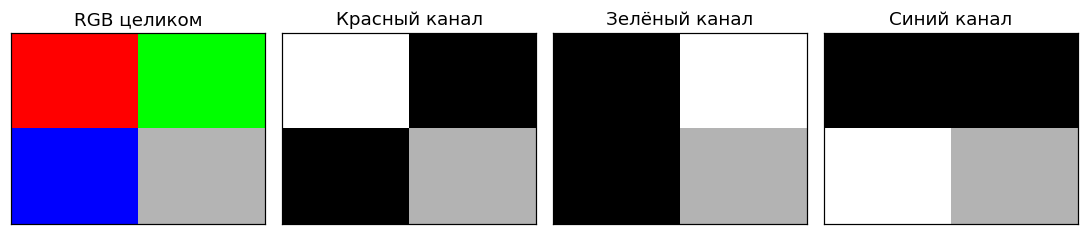

In [3]:
rgb_tensor = torch.from_numpy(loaded_rgb).float() / 255.0
rgb_batch = rgb_tensor.permute(2, 0, 1).unsqueeze(0)
print('До перестановки:', tuple(rgb_tensor.shape))
print('Пакет N, C, H, W:', tuple(rgb_batch.shape))

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
axes[0].imshow(loaded_rgb)
axes[0].set_title('RGB целиком')
for channel, name in enumerate(['Красный канал', 'Зелёный канал', 'Синий канал']):
    axes[channel + 1].imshow(loaded_rgb[:, :, channel], cmap='gray', vmin=0, vmax=255)
    axes[channel + 1].set_title(name)
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()

**Разбор кода и каналов.**

- `torch.from_numpy(...)` создаёт тензорное представление массива. `.float()` переводит значения в дробный тип; деление на `255.0` масштабирует их в диапазон от 0 до 1. Это правило нашего примера; у готовой модели подготовка может быть другой.
- `.permute(2, 0, 1)` переставляет оси: прежняя третья ось каналов становится первой. Отсчёт осей начинается с нуля. `.unsqueeze(0)` добавляет новую первую ось размером 1 — пакет из одного изображения. `tuple(...)`, `.shape` и `print(...)` показывают формы.
- `N, C, H, W` означают число изображений, каналов, высоту и ширину. Получается `(1, 3, 24, 32)`. Перестановка осей сохраняет расположение значений внутри соответствующих каналов; обычный `reshape` не заменяет её.
- `plt.subplots(...)` создаёт рисунок и четыре панели. `imshow(...)` показывает RGB или выбранный канал. `loaded_rgb[:, :, channel]` оставляет все строки и столбцы и выбирает один канал.
- `enumerate(...)` выдаёт номер и название, `for` повторяет действия. `channel + 1` пропускает первую панель с исходным RGB. `cmap='gray'`, `vmin=0`, `vmax=255` задают общий способ показа каналов: светлое означает высокое значение выбранного цвета.
- `set_title(...)` подписывает панели; `set_xticks([])` и `set_yticks([])` убирают деления, сохраняя рамку изображения, чтобы белые области не сливались с фоном; `tight_layout()` размещает элементы, `plt.show()` выводит рисунок.

Изображение канала показано серым, потому что мы изучаем его интенсивность. Это не превращает исходный RGB в обычную серую фотографию: три отдельных канала продолжают хранить разную информацию.

## 2. Как CNN выделяет пространственные признаки

Свёрточная сеть сохраняет связь между соседними пикселями. **Ядро, или фильтр**, просматривает небольшие участки изображения; одни и те же обучаемые веса применяются в разных положениях. Получается **карта признака** — пространственный отклик фильтра. Один выходной канал соответствует одной такой карте.

В первом слое фильтр использует входные цветовые каналы совместно. В следующих слоях входом становятся карты предыдущих слоёв. По мере прохождения сети признаки могут объединять информацию всё более крупных областей — это называют увеличением **рецептивного поля**. Оно описывает область входа, способную повлиять на конкретный выход.

**Размер ядра** задаёт локальное окно. **Stride** — шаг его перемещения. **Padding** — добавляемая рамка вокруг входа. **Pooling** уменьшает пространственный размер; Max Pooling сохраняет наиболее сильный отклик в каждом окне. Эти действия меняют представление изображения, а не создают новый обучающий объект.

Сначала зададим фильтр вручную: он будет реагировать на вертикальную границу между тёмной и светлой областями. Так проще увидеть работу одного локального фильтра. Этот фильтр не обучается и не является готовым распознавателем объектов.

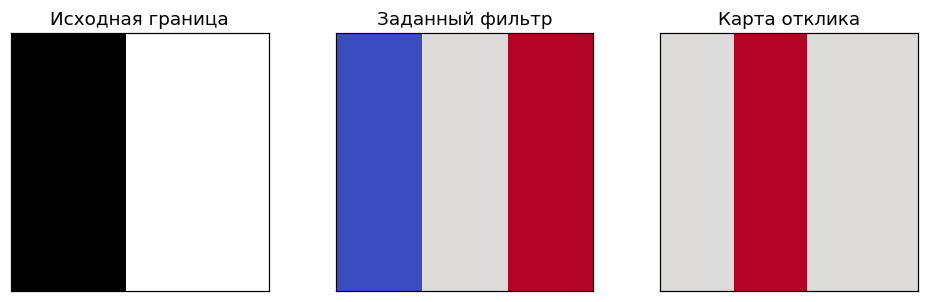

Вход: (1, 1, 9, 9) | выход: (1, 1, 7, 7)


In [4]:
edge_image = torch.zeros(1, 1, 9, 9)
edge_image[:, :, :, 4:] = 1.0
edge_kernel = torch.tensor([[-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0]])
edge_conv = nn.Conv2d(1, 1, kernel_size=3, padding=0, bias=False)
with torch.no_grad():
    edge_conv.weight.copy_(edge_kernel.reshape(1, 1, 3, 3))
    edge_response = edge_conv(edge_image)

fig, axes = plt.subplots(1, 3, figsize=(9, 2.8))
axes[0].imshow(edge_image[0, 0].numpy(), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Исходная граница')
axes[1].imshow(edge_kernel.numpy(), cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_title('Заданный фильтр')
axes[2].imshow(edge_response[0, 0].numpy(), cmap='coolwarm', vmin=-3, vmax=3)
axes[2].set_title('Карта отклика')
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()
print('Вход:', tuple(edge_image.shape), '| выход:', tuple(edge_response.shape))

**Разбор кода и отклика.**

- `torch.zeros(1, 1, 9, 9)` создаёт пакет из одного одноканального изображения. Срез `[:, :, :, 4:]` выбирает столбцы начиная с индекса 4; присваивание делает правую часть светлой. `torch.tensor(...)` создаёт ядро из вложенных списков.
- `nn.Conv2d(1, 1, kernel_size=3, padding=0, bias=False)` задаёт один входной и один выходной канал, окно 3 на 3, отсутствие дополнительной рамки и смещения. По умолчанию шаг равен 1.
- В `torch.no_grad()` метод `.weight.copy_(...)` записывает наши числа в веса слоя без построения графа для этого действия. Подчёркивание в конце имени метода означает изменение объекта на месте. `.reshape(1, 1, 3, 3)` согласует форму с весами Conv2d: выходные каналы, входные каналы, высота и ширина ядра.
- `edge_conv(edge_image)` вызывает слой на входе. `.numpy()` готовит значения для `imshow(...)`; `[0, 0]` выбирает первое изображение и его единственную карту. Общие `vmin` и `vmax` задают смысл цветов; нулевой отклик близок к нейтральному цвету карты.
- `plt.subplots(...)`, `set_title(...)`, `set_xticks([])`, `set_yticks([])`, `tight_layout()` и `plt.show()` оформляют три панели. Пустые списки убирают деления осей, но оставляют границы изображения; цикл `for` применяет общую настройку. `tuple(...)`, `.shape` и `print(...)` показывают размеры.

Отклик возникает возле вертикального перехода. Выход меньше входа, поскольку без padding окно не выходит за край. В обучаемой CNN ядра подбираются по данным; ручной пример объясняет операцию, а не заменяет обучение.

Сравним формы выхода одной свёртки при разных padding и stride. Во всех строках используются одно и то же изображение и окно 3 на 3. Числовые отклики разных случайных фильтров здесь не сравниваем: рассматриваем только размеры.

In [5]:
shape_rows = []
for padding, stride in [(0, 1), (1, 1), (1, 2)]:
    shape_layer = nn.Conv2d(1, 1, kernel_size=3, padding=padding, stride=stride)
    with torch.no_grad():
        shape_output = shape_layer(edge_image)
    shape_rows.append({
        'Padding': padding,
        'Stride': stride,
        'Форма входа': str(tuple(edge_image.shape)),
        'Форма выхода': str(tuple(shape_output.shape)),
    })
display(pd.DataFrame(shape_rows))

,Padding,Stride,Форма входа,Форма выхода
0,0,1,"(1, 1, 9, 9)","(1, 1, 7, 7)"
1,1,1,"(1, 1, 9, 9)","(1, 1, 9, 9)"
2,1,2,"(1, 1, 9, 9)","(1, 1, 5, 5)"


**Разбор кода и размеров.**

- `shape_rows = []` создаёт пустой список для строк. Цикл `for padding, stride in [...]` перебирает список кортежей и распаковывает два числа в две переменные.
- `nn.Conv2d(...)` получает текущие `padding` и `stride`. Имена слева от `=` — параметры конструктора, справа — значения переменных. Остальные параметры сохраняются между вариантами.
- `torch.no_grad()` оставляет только получение выхода; `shape_layer(edge_image)` вызывает текущий слой. Новая модель создаётся в каждой итерации, но веса нам нужны лишь для выполнения операции с заданной формой.
- `.append({...})` добавляет словарь в список. `.shape` читает размеры, `tuple(...)` и `str(...)` превращают их в удобную строку. `pd.DataFrame(...)` собирает таблицу из словарей, `display(...)` выводит её.

С padding 0 размер становится 7 на 7; с padding 1 и шагом 1 сохраняются 9 на 9; шаг 2 уменьшает выход до 5 на 5. Padding и stride управляют пространственным размером, а не числом выходных каналов.

Соберём короткую цепочку для RGB: свёртка создаст четыре карты, ReLU обработает их, а Max Pooling уменьшит высоту и ширину. Проследим форму после каждого слоя. Здесь веса случайные: это демонстрация структуры перед обучением.

In [6]:
spatial_demo = nn.Sequential(
    nn.Conv2d(3, 4, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
)
spatial_rows = [{'Этап': 'Вход RGB', 'Форма': str(tuple(rgb_batch.shape))}]
spatial_values = rgb_batch
with torch.no_grad():
    for layer in spatial_demo:
        spatial_values = layer(spatial_values)
        spatial_rows.append({'Этап': type(layer).__name__, 'Форма': str(tuple(spatial_values.shape))})
display(pd.DataFrame(spatial_rows))

,Этап,Форма
0,Вход RGB,"(1, 3, 24, 32)"
1,Conv2d,"(1, 4, 24, 32)"
2,ReLU,"(1, 4, 24, 32)"
3,MaxPool2d,"(1, 4, 12, 16)"


**Разбор кода и цепочки.**

- `nn.Sequential(...)` создаёт упорядоченную цепочку. `nn.Conv2d(3, 4, ...)` принимает три RGB-канала и выдаёт четыре карты. В обычной свёртке каждый из четырёх выходных фильтров использует все три входных канала.
- `nn.ReLU()` — уже знакомая активация; здесь она сохраняет форму. `nn.MaxPool2d(kernel_size=2)` выбирает наиболее сильные отклики в окнах 2 на 2. По умолчанию шаг равен размеру этого окна, поэтому пространственный размер уменьшается вдвое.
- Список `spatial_rows` начинает таблицу строкой входа. Присваивание `spatial_values = rgb_batch` задаёт текущее представление. Цикл `for layer in spatial_demo` перебирает объекты слоёв.
- `layer(spatial_values)` применяет очередной слой; результат становится входом следующего. Контекст `torch.no_grad()` отключает запись графа. `.append(...)`, `tuple(...)`, `str(...)` и `.shape` формируют строки размеров.
- `type(layer).__name__` получает название класса текущего слоя. `pd.DataFrame(...)` и `display(...)` показывают таблицу.

На выходе `(1, 4, 12, 16)`: четыре карты вместо трёх каналов и уменьшенные пространственные размеры. Четыре карты ещё не означают четыре класса. Число классов задаётся отдельной выходной частью модели.

## 3. Небольшая обученная CNN

Теперь фильтры будут обучаемыми. Используем изображения рукописных цифр размером 8 на 8 из `load_digits`. Для исходной задачи возьмём только цифры **0–4**. Цифры **6 и 9** оставим для другой задачи в разделе transfer learning.

Сеть состоит из **выделителя признаков** и **классификационной головы**. Первые слои получают пространственные карты. `Flatten` разворачивает готовые карты в набор признаков объекта, а последний `Linear` выдаёт по одному логиту на класс. Подготовка и проверка выполняются раздельно; теорию метрик и разбиения здесь не повторяем.

Загрузим встроенные цифры, добавим ось канала и выделим исходные классы 0–4. Их изображения разделим на обучение и валидацию. Покажем по одному примеру каждого класса, чтобы связать числовой вход с изображением.

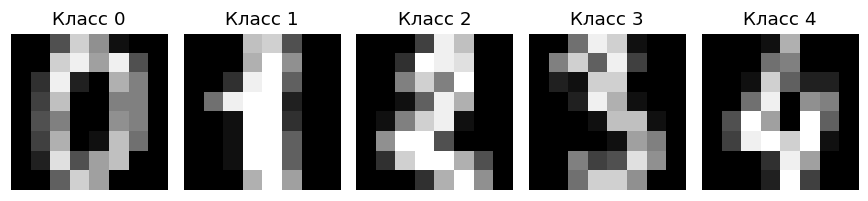

Обучение: (675, 1, 8, 8)
Валидация: (226, 1, 8, 8)


In [7]:
digits = load_digits()
all_images = torch.from_numpy(digits.images.astype(np.float32) / 16.0).unsqueeze(1)
all_labels = torch.from_numpy(digits.target).long()
source_indices = np.flatnonzero(digits.target < 5)
source_train_indices, source_valid_indices = train_test_split(
    source_indices, test_size=0.25, stratify=digits.target[source_indices], random_state=31
)
source_train_images = all_images[source_train_indices]
source_train_labels = all_labels[source_train_indices]
source_valid_images = all_images[source_valid_indices]
source_valid_labels = all_labels[source_valid_indices]

fig, axes = plt.subplots(1, 5, figsize=(8, 2.1))
for label, ax in enumerate(axes):
    image_index = np.flatnonzero(digits.target == label)[0]
    ax.imshow(digits.images[image_index], cmap='gray', vmin=0, vmax=16)
    ax.set_title(f'Класс {label}')
    ax.axis('off')
fig.tight_layout()
plt.show()
print('Обучение:', tuple(source_train_images.shape))
print('Валидация:', tuple(source_valid_images.shape))

**Разбор кода и разбиения.**

- `load_digits()` возвращает небольшой встроенный набор без интернет-загрузки. `.images` содержит изображения, `.target` — правильные цифры. Их исходные интенсивности лежат от 0 до 16, поэтому для этого набора используется деление на `16.0`, а не на 255.
- `.astype(np.float32)` согласует дробный тип, `torch.from_numpy(...)` создаёт тензор, `.unsqueeze(1)` добавляет канал: получается формат `N, 1, 8, 8`. `.long()` задаёт целочисленный тип меток, нужный `CrossEntropyLoss`.
- Сравнение `digits.target < 5` создаёт маску классов. `np.flatnonzero(...)` возвращает индексы подходящих строк. `train_test_split(...)` делит индексы с учётом классов через `stratify`; `test_size` задаёт долю валидации, `random_state` фиксирует разбиение.
- Записи `all_images[source_train_indices]` и подобные выбирают связанные изображения и ответы по одним индексам. Присваивания сохраняют четыре части в отдельных переменных.
- `plt.subplots(...)` создаёт панели, `enumerate(axes)` даёт номер класса и панель. `np.flatnonzero(digits.target == label)[0]` находит первый пример текущего класса. `imshow(...)` показывает его, `f'Класс {label}'` подставляет номер в подпись `set_title(...)`.
- `axis(...)`, `tight_layout()` и `plt.show()` оформляют рисунок; `.shape`, `tuple(...)` и `print(...)` показывают размеры частей.

Валидационные изображения не участвуют в обучении исходной CNN. Другие цифры в этот этап также не передаются. У этой задачи один канал и пять классов; это разные характеристики входа и выхода.

Опишем небольшую CNN с двумя свёртками. После двух уменьшений 8 на 8 превращается в 2 на 2; у 16 карт остаётся 64 значения для головы. Отдельные атрибуты `features` и `classifier` понадобятся, когда будем переносить обученные признаки.

In [8]:
class DigitCNN(nn.Module):
    def __init__(self, classes=5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
        )
        self.classifier = nn.Linear(64, classes)

    def forward(self, images):
        return self.classifier(self.features(images))

torch.manual_seed(23)
source_cnn = DigitCNN(classes=5)
with torch.no_grad():
    source_feature_sample = source_cnn.features(source_train_images[:2])
    source_output_sample = source_cnn(source_train_images[:2])
print(source_cnn)
print('Признаки двух изображений:', tuple(source_feature_sample.shape))
print('Логиты двух изображений:', tuple(source_output_sample.shape))
print('Параметров:', sum(parameter.numel() for parameter in source_cnn.parameters()))

DigitCNN(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (classifier): Linear(in_features=64, out_features=5, bias=True)
)
Признаки двух изображений: (2, 64)
Логиты двух изображений: (2, 5)
Параметров: 1573


**Разбор класса и размеров.**

- `class DigitCNN(nn.Module):` определяет собственный класс сети на основе `nn.Module`. `def __init__(self, classes=5):` задаёт создание экземпляра; `self` обозначает этот экземпляр, `classes` получает значение 5 по умолчанию. `super().__init__()` инициализирует механизмы родительского модуля.
- `self.features` хранит `nn.Sequential` со свёртками, `nn.ReLU`, `nn.MaxPool2d` и `nn.Flatten`. Первая Conv2d создаёт 8 карт из одного канала, вторая — 16 из восьми. Padding сохраняет размеры перед pooling.
- `nn.Flatten()` сохраняет ось пакета и объединяет остальные: каждое изображение становится строкой из 64 признаков. `nn.Linear(64, classes)` создаёт голову с нужным числом выходов. Итоговые пять логитов не являются пятью изображениями.
- `def forward(self, images):` определяет прямой проход. В выражении `return self.classifier(self.features(images))` внутренний вызов получает признаки, затем `self.classifier(...)` применяет голову. `return` возвращает результат наружу. Вызов объекта `source_cnn(...)` запускает этот `forward` через механизмы `nn.Module`.
- `torch.manual_seed(23)` повторно фиксирует начальное состояние непосредственно перед созданием CNN, независимо от демонстрационных случайных слоёв выше. `DigitCNN(classes=5)` создаёт объект. Срез `[:2]` берёт два изображения; в `torch.no_grad()` проверяем формы без записи графа.
- `.parameters()` перечисляет параметры, `.numel()` считает числа, `sum(... for ... in ...)` суммирует их. `.shape`, `tuple(...)` и `print(...)` показывают структуру и размер.

У модели 1 573 параметра. На этой стадии они ещё не обучены; проверка форм показывает лишь согласованность слоёв.

Запишем короткую функцию обучения и применим её к исходной CNN. Знакомый шаг обучения будет повторяться по пакетам изображений. Функция выбирает только параметры, для которых разрешено обучение: это позволит затем использовать тот же код с замороженными признаками.

In [9]:
def fit_image_classifier(model, images, labels, epochs, learning_rate):
    dataset = TensorDataset(images, labels)
    loader = DataLoader(
        dataset, batch_size=64, shuffle=True,
        generator=torch.Generator().manual_seed(67), num_workers=0,
    )
    trainable_parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
    optimizer = torch.optim.Adam(trainable_parameters, lr=learning_rate)
    criterion = nn.CrossEntropyLoss()
    history_rows = []
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for batch_images, batch_labels in loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_images)
            loss = criterion(logits, batch_labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch_images)
        history_rows.append({'Эпоха': epoch, 'Потеря': total_loss / len(dataset)})
    model.eval()
    return pd.DataFrame(history_rows).set_index('Эпоха')

source_history = fit_image_classifier(
    source_cnn, source_train_images, source_train_labels, epochs=25, learning_rate=0.01
)
display(source_history.loc[[1, 5, 15, 25]])

,Потеря
Эпоха,
1,1.4946
5,0.0721
15,0.0063
25,0.0016


**Разбор функции и обучения.**

- `def fit_image_classifier(...):` определяет функцию; её тело задаётся отступом. Аргументы — модель, изображения, метки, число эпох и шаг. `TensorDataset(...)` связывает входы с ответами, `DataLoader(...)` выдаёт перемешанные пакеты до 64 изображений. `num_workers=0` не запускает дополнительные процессы.
- `torch.Generator().manual_seed(67)` создаёт отдельный генератор порядка пакетов. Список `[parameter for parameter in model.parameters() if parameter.requires_grad]` перебирает параметры и сохраняет лишь те, у которых обучение разрешено. `if` здесь — условие отбора в списке.
- `torch.optim.Adam(..., lr=learning_rate)` создаёт оптимизатор для выбранных параметров. `nn.CrossEntropyLoss()` принимает логиты пяти классов и целочисленные ответы. В каждом новом вызове функции создаётся свой оптимизатор.
- `range(1, epochs + 1)` даёт номера эпох, `model.train()` включает обучающий режим. Внутренний `for` распаковывает очередные изображения и метки. `zero_grad(set_to_none=True)` очищает прежние градиенты; вызов модели получает логиты, `criterion(...)` — потерю, `backward()` — градиенты, `step()` обновляет разрешённые веса.
- `.item()` читает число из потери пакета. `total_loss += ...` добавляет вклад с учётом размера пакета через `len(...)`. Деление на размер всего `dataset` даёт отчётную потерю эпохи, включая меньший последний пакет.
- `.append({...})` добавляет строку истории. `model.eval()` в конце включает режим получения ответов. `return pd.DataFrame(...).set_index('Эпоха')` возвращает таблицу, `.loc[[...]]` выбирает номера эпох, `display(...)` выводит их.

Обучение выполняется 25 эпох по заданной конфигурации. Валидация в функцию не передаётся и не выбирает настройки обучения. Для последующих этапов число эпох и шаг тоже заданы заранее.

В конце 25-й эпохи обучающая потеря около 0,0016. Это итог обновлений на 675 обучающих изображениях; качество на других изображениях проверяется отдельно в следующем примере.

Проверим исходную CNN на её валидационной части. Получим классы из выходных логитов, посчитаем знакомую accuracy и покажем несколько изображений с правильным и предсказанным ответом. Это проверка распознавания целого изображения, без рамок объектов.

Accuracy исходной CNN: 0.9956


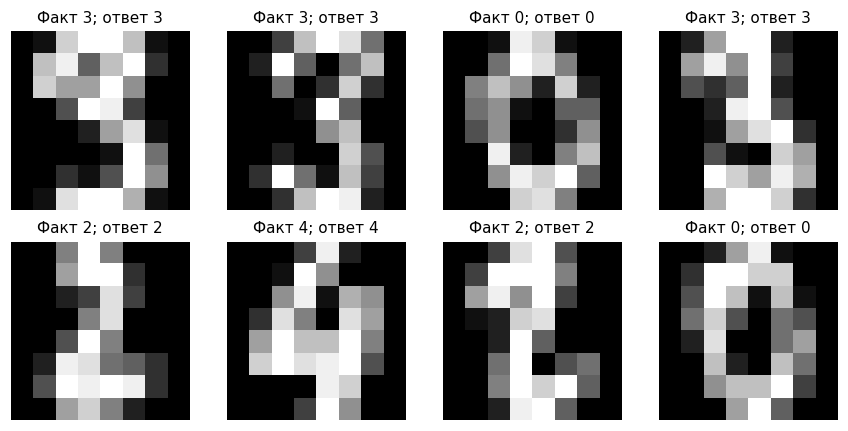

In [10]:
source_cnn.eval()
with torch.no_grad():
    source_valid_logits = source_cnn(source_valid_images)
    source_predictions = source_valid_logits.argmax(dim=1).numpy()
source_accuracy = accuracy_score(source_valid_labels.numpy(), source_predictions)
print('Accuracy исходной CNN:', round(source_accuracy, 4))

fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for position, ax in enumerate(axes.ravel()):
    ax.imshow(source_valid_images[position, 0].numpy(), cmap='gray', vmin=0, vmax=1)
    fact = int(source_valid_labels[position])
    prediction = int(source_predictions[position])
    ax.set_title(f'Факт {fact}; ответ {prediction}', fontsize=10)
    ax.axis('off')
fig.tight_layout()
plt.show()

**Разбор проверки и ответов.**

- `.eval()` задаёт режим получения ответов; `torch.no_grad()` отключает запись графа. `source_cnn(source_valid_images)` применяет обученную сеть к отдельным изображениям.
- `.argmax(dim=1)` выбирает номер наибольшего логита по оси классов. В исходной задаче номера 0–4 совпадают с названиями цифр. `.numpy()` переводит значения в массив для `accuracy_score(...)`; `round(..., 4)` округляет показатель, `print(...)` выводит его.
- `plt.subplots(2, 4, ...)` создаёт восемь панелей. `axes.ravel()` разворачивает массив панелей в одну последовательность, `enumerate(...)` выдаёт позицию и панель.
- `[position, 0]` выбирает изображение и единственный канал; `imshow(...)` показывает его с единым диапазоном интенсивности. `int(...)` получает обычное целое число для подписи, строка `f'...'` подставляет факт и ответ.
- `set_title(...)`, `axis(...)`, `tight_layout()` и `plt.show()` оформляют рисунок.

Эти ответы относятся к цифрам 0–4 размером 8 на 8 из данного набора. По ним нельзя заключать, что модель уже читает произвольные фотографии документов или умеет находить несколько цифр в сцене.

В сохранённом запуске accuracy около 0,9956: верно распознаны 225 из 226 валидационных изображений. Показанные восемь примеров не исчерпывают валидацию: показатель рассчитан по всей её части.

Посмотрим несколько карт первого обученного слоя для одного валидационного изображения. Сравним исходную цифру с четырьмя каналами после свёртки и ReLU. В отличие от ручного фильтра, эти веса были подобраны при обучении CNN.

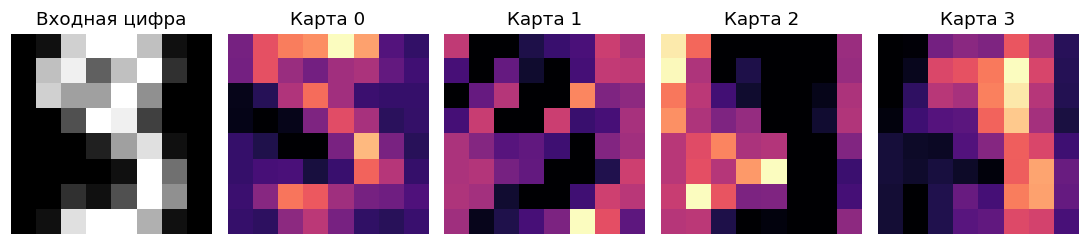

Все карты первого слоя: (8, 8, 8)


In [11]:
with torch.no_grad():
    learned_maps = source_cnn.features[:2](source_valid_images[:1])[0]
fig, axes = plt.subplots(1, 5, figsize=(10, 2.6))
axes[0].imshow(source_valid_images[0, 0].numpy(), cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Входная цифра')
for channel in range(4):
    axes[channel + 1].imshow(learned_maps[channel].numpy(), cmap='magma')
    axes[channel + 1].set_title(f'Карта {channel}')
for ax in axes:
    ax.axis('off')
fig.tight_layout()
plt.show()
print('Все карты первого слоя:', tuple(learned_maps.shape))

**Разбор кода и карт признаков.**

- `source_cnn.features[:2]` выбирает первые два слоя `Sequential`: обученную свёртку и ReLU. `source_valid_images[:1]` сохраняет ось пакета при выборе одного изображения. Последующий `[0]` убирает её из результата.
- В `torch.no_grad()` вычисляются карты без нового графа. Их форма `(8, 8, 8)` здесь означает восемь каналов высотой и шириной 8; одинаковые числа не делают назначение осей одинаковым.
- `plt.subplots(...)` создаёт пять панелей, `[0, 0]` выбирает исходную цифру. `range(4)` и `for` показывают четыре из восьми каналов. `[channel]` выбирает одну карту; `.numpy()` готовит её к `imshow(...)`.
- `cmap='magma'` задаёт цветовую палитру откликов. У каждой карты собственный цветовой масштаб: по этим цветам сравниваем пространственный рисунок внутри карты, а не абсолютную силу разных каналов.
- `set_title(...)` со строкой `f'...'` подписывает карты. Общий цикл задаёт `axis('off')`, `tight_layout()` размещает панели, `plt.show()` выводит рисунок. `tuple(...)`, `.shape` и `print(...)` показывают все размерности.

Карта признака не обязана соответствовать понятному человеку имени вроде «петля цифры». Это промежуточный отклик, который последующие слои используют совместно с другими каналами.

## 4. Архитектуры VGG и ResNet

### VGG: последовательные блоки свёрток

VGG использует последовательности небольших свёрток 3 на 3, разделённые уменьшением пространственных размеров. В классической VGG-16 пять групп содержат 2, 2, 3, 3 и 3 свёртки, затем следует полносвязная классификационная часть. Число 16 относится к 13 свёрточным и трём полносвязным слоям с весами. Каналы в группах: 64, 128, 256, 512, 512. [Исходная работа VGG](https://arxiv.org/abs/1409.1556).

VGG полезна как ясный пример последовательной архитектуры. Полная классификационная часть содержит много параметров; глубина сама по себе не задаёт расход памяти или качество. Маленький блок ниже повторяет характерную последовательность операций, но имеет меньше каналов, чем настоящая VGG-16.

Выполним компактный блок в стиле VGG на нашем RGB-изображении: две свёртки с ReLU, затем одно уменьшение размера. Покажем переходы форм. Это отдельный пример структуры; эти случайные веса не используются для распознавания изображения.

In [12]:
vgg_style_block = nn.Sequential(
    nn.Conv2d(3, 8, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(8, 8, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),
)
vgg_block_rows = []
vgg_values = rgb_batch
with torch.no_grad():
    for position, layer in enumerate(vgg_style_block, start=1):
        vgg_values = layer(vgg_values)
        vgg_block_rows.append({
            'Шаг': position, 'Слой': type(layer).__name__, 'Форма': str(tuple(vgg_values.shape))
        })
display(pd.DataFrame(vgg_block_rows).set_index('Шаг'))

,Слой,Форма
Шаг,,
1,Conv2d,"(1, 8, 24, 32)"
2,ReLU,"(1, 8, 24, 32)"
3,Conv2d,"(1, 8, 24, 32)"
4,ReLU,"(1, 8, 24, 32)"
5,MaxPool2d,"(1, 8, 12, 16)"


**Разбор блока VGG.**

- `nn.Sequential(...)` располагает слои последовательно. Первый `nn.Conv2d` переводит RGB в восемь каналов, второй сохраняет их число. `kernel_size=3` и `padding=1` сохраняют высоту и ширину перед pooling.
- После каждой свёртки стоит `nn.ReLU()`. Затем `nn.MaxPool2d(2)` уменьшает пространственные размеры. Это несколько локальных преобразований до следующего уменьшения.
- `vgg_block_rows = []` создаёт список строк, `vgg_values` хранит текущее представление. В `torch.no_grad()` цикл `enumerate(..., start=1)` перебирает слои и добавляет номера с единицы.
- `layer(vgg_values)` получает очередной выход. `.append({...})`, `type(...).__name__`, `.shape`, `tuple(...)` и `str(...)` записывают название и размеры. `pd.DataFrame(...).set_index('Шаг')` создаёт подписанную таблицу, `display(...)` показывает её.

Две свёртки сохраняют размеры 24 на 32; pooling даёт 12 на 16. В VGG таких групп несколько, причём число каналов меняется между группами. Этот блок поясняет её организацию, а не является всей архитектурой.

### ResNet: путь в обход преобразований

В ResNet используются **остаточные связи, или skip connections**. Вход блока проходит по основному пути со слоями и одновременно по короткому обходному пути. Затем представления складываются. Это позволяет блоку учить изменение уже имеющегося представления и облегчает обучение глубоких сетей. [Исходная работа ResNet](https://arxiv.org/abs/1512.03385).

Для сложения размеры ветвей должны совпадать. При изменении числа каналов или пространственного размера в обходной ветви используют согласующее преобразование, часто свёртку 1 на 1 с нужным шагом. Свёртка 1 на 1 работает по каналам в каждой позиции и сама по себе не означает уменьшение изображения.

В ResNet-18 четыре основные группы содержат по два остаточных блока. У блоков есть дополнительные детали, включая уже знакомую Batch Normalization. Учебный блок ниже оставляет только механизм обходной связи, чтобы увидеть его отдельно.

Создадим упрощённый остаточный блок с совпадающими размерами ветвей. Для наглядности сделаем последний фильтр основной ветви нулевым и подадим неотрицательный вход. Тогда основная ветвь не внесёт изменений, и сможем проверить сохранение входа через обходной путь.

In [13]:
class SimpleResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.branch = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.ReLU(),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
        )
        self.activation = nn.ReLU()

    def forward(self, features):
        return self.activation(features + self.branch(features))

residual_block = SimpleResidualBlock(channels=8)
nn.init.zeros_(residual_block.branch[2].weight)
residual_input = torch.rand(1, 8, 8, 8)
with torch.no_grad():
    residual_output = residual_block(residual_input)
print('Вход:', tuple(residual_input.shape), '| выход:', tuple(residual_output.shape))
print('Неотрицательный вход сохранился:', torch.allclose(residual_input, residual_output))

Вход: (1, 8, 8, 8) | выход: (1, 8, 8, 8)
Неотрицательный вход сохранился: True


**Разбор остаточной связи.**

- `class SimpleResidualBlock(nn.Module):` определяет модуль. Метод `__init__`, аргумент `self` и `super().__init__()` создают его внутренние слои и регистрируют их в PyTorch.
- `self.branch = nn.Sequential(...)` хранит преобразующую ветвь: два `nn.Conv2d` с промежуточным `nn.ReLU`. Число каналов одинаково на входе и выходе; `padding=1` сохраняет пространственные размеры. `bias=False` исключает отдельное смещение.
- В `forward` выражение `features + self.branch(features)` складывает вход с выходом ветви в совпадающих позициях. `self.activation(...)` применяет ReLU после соединения; `return` возвращает выход. Обходная связь выражена непосредственным использованием `features`.
- `SimpleResidualBlock(channels=8)` создаёт экземпляр. `[2]` выбирает последний слой ветви, `.weight` — его веса. `nn.init.zeros_(...)` заполняет их нулями. Это специальная демонстрационная настройка, а не предписание для всей ResNet.
- `torch.rand(...)` создаёт неотрицательные значения от 0 до 1. В `torch.no_grad()` вызов `residual_block(...)` выполняет проход. `torch.allclose(...)` проверяет числовую близость, `.shape`, `tuple(...)` и `print(...)` показывают формы и результат.

Проверка даёт `True`: ветвь не добавляет изменения, а ReLU сохраняет выбранный неотрицательный вход. С отрицательным входом последняя ReLU могла бы изменить значения. Наличие skip connection не означает, что любой обученный блок всегда возвращает исходные данные.

Теперь создадим полные стандартные VGG-16 и ResNet-18 из Torchvision и проверим их размеры. Используем устройство `meta`: оно хранит структуру и формы без массивов значений весов. Это позволяет рассмотреть большую VGG без выделения памяти под все её веса. Здесь выполняется проверка структуры, а не числовое распознавание.

In [14]:
with torch.device('meta'):
    full_vgg = vgg16(weights=None).eval()
    full_resnet = resnet18(weights=None).eval()
    architecture_input = torch.empty(1, 3, 224, 224)
    vgg_output_shape = tuple(full_vgg(architecture_input).shape)
    resnet_output_shape = tuple(full_resnet(architecture_input).shape)

architecture_table = pd.DataFrame([
    {'Архитектура': 'VGG-16', 'Параметров': sum(p.numel() for p in full_vgg.parameters()),
     'Форма выхода': str(vgg_output_shape), 'Режим': 'meta: только структура'},
    {'Архитектура': 'ResNet-18', 'Параметров': sum(p.numel() for p in full_resnet.parameters()),
     'Форма выхода': str(resnet_output_shape), 'Режим': 'meta: только структура'},
]).set_index('Архитектура')
display(architecture_table)

,Параметров,Форма выхода,Режим
Архитектура,,,
VGG-16,138357544,"(1, 1000)",meta: только структура
ResNet-18,11689512,"(1, 1000)",meta: только структура


**Разбор полных архитектур.**

- `with torch.device('meta'):` задаёт специальное устройство для создаваемых внутри тензоров. У них есть форма и тип, но нет числовых данных весов. Это описанный в [справке PyTorch режим meta](https://docs.pytorch.org/docs/2.11/meta.html).
- `vgg16(weights=None)` и `resnet18(weights=None)` строят стандартные архитектуры; `None` означает отсутствие загрузки предобученных весов. `.eval()` задаёт проверочное поведение слоёв. В этом контексте обе модели существуют как структура.
- `torch.empty(1, 3, 224, 224)` создаёт описание входа: одно RGB-изображение 224 на 224. Вызовы `full_vgg(...)` и `full_resnet(...)` проводят информацию о формах через слои. `tuple(...shape)` получает форму выхода без реальных логитов.
- `.parameters()`, `.numel()` и `sum(... for ... in ...)` считают размеры параметров даже без их значений. `str(...)` готовит форму для таблицы. `pd.DataFrame(...).set_index(...)` подписывает строки, `display(...)` показывает результат.

Получаются 138 357 544 параметра VGG-16 и 11 689 512 у ResNet-18. Выход `(1, 1000)` соответствует стандартной классификационной голове на 1 000 классов. Эти объекты не обучены и не дают пригодных предсказаний: на `meta` мы проверили только устройство моделей. Для настоящего переноса нужны обученные числовые веса, как в следующем разделе.

## 5. Transfer learning: перенос обученных признаков

При **переносе обучения** используются веса, уже обученные на исходной задаче. Выделитель признаков становится отправной точкой для другой задачи, а голову обычно заменяют под новые классы. Создание той же архитектуры со случайными весами само по себе не является переносом знаний.

| Режим | Что обучается на новой задаче | Для чего используем в примере |
|---|---|---|
| Замороженные признаки | Только новая голова | Сохраняем исходные признаки и учим различать новые классы |
| Дообучение, fine-tuning | Голова и выбранные прежние слои | Разрешаем части признаков немного измениться под новую задачу |

Используем **реально обученную `source_cnn`**, а не веса ImageNet. На исходном этапе она видела только 0–4. Теперь её признаки будут различать **6 и 9** по 40 обучающим изображениям. Это маленький пример переноса между связанными задачами; он не обещает такой же результат при переносе на медицинские снимки или фотографии улиц.

В практике с готовыми весами также нужно сохранять ожидаемые цветовые каналы, масштаб и нормализацию выбранной модели. У предобученных моделей Torchvision эти правила связаны с конкретным набором весов. Общий подход описан в [руководстве PyTorch по переносу обучения](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html).

Подготовим новую задачу «6 или 9». Выделим ровно 40 обучающих изображений с сохранением долей классов, остальные оставим для валидации. Покажем соответствие новых меток цифрам и проверим, что изображения новой задачи не входили в исходную задачу 0–4.

In [15]:
target_indices = np.flatnonzero(np.isin(digits.target, [6, 9]))
target_train_indices, target_valid_indices = train_test_split(
    target_indices, train_size=40, stratify=digits.target[target_indices], random_state=41
)
target_train_images = all_images[target_train_indices]
target_valid_images = all_images[target_valid_indices]
target_train_labels = torch.from_numpy((digits.target[target_train_indices] == 9).astype(np.int64))
target_valid_labels = torch.from_numpy((digits.target[target_valid_indices] == 9).astype(np.int64))

display(pd.DataFrame({
    'Часть': ['Обучение', 'Валидация'],
    'Изображений': [len(target_train_indices), len(target_valid_indices)],
}))
print('Метки новой головы: 0 → цифра 6; 1 → цифра 9')
print('Пересечений с исходной задачей:', len(np.intersect1d(source_indices, target_indices)))

,Часть,Изображений
0,Обучение,40
1,Валидация,321


Метки новой головы: 0 → цифра 6; 1 → цифра 9
Пересечений с исходной задачей: 0


**Разбор новой задачи.**

- `np.isin(digits.target, [6, 9])` создаёт маску двух выбранных цифр, `np.flatnonzero(...)` получает их индексы. `train_test_split(..., train_size=40, ...)` выделяет заданное количество обучающих строк; `stratify` учитывает классы, `random_state=41` фиксирует разбиение.
- Индексы в квадратных скобках выбирают изображения из `all_images`. Правило подготовки уже выполнено выше, поэтому новый этап не меняет их масштаб и порядок осей.
- Выражение `== 9` даёт `True` для девятки и `False` для шестёрки. `.astype(np.int64)` превращает их в целые 1 и 0, `torch.from_numpy(...)` создаёт тензор меток. Так у новой головы два последовательных номера классов.
- `pd.DataFrame({...})`, `len(...)` и `display(...)` показывают размеры частей. `np.intersect1d(...)` находит общие индексы двух наборов; его длина должна быть нулевой. `print(...)` показывает проверку и явное соответствие меток цифрам.

Изображения новой валидации не использовались ни при обучении исходной CNN, ни при выделении 40 новых обучающих примеров. Метка `1` новой головы означает цифру 9, а не прежнюю цифру 1.

Скопируем обученную CNN, запретим изменение прежних весов и заменим голову на два выхода. Исходная модель останется отдельным объектом. Сохраним снимки параметров, чтобы после обучения проверить реальное замораживание, а не только посмотреть на настройку флага.

In [16]:
torch.manual_seed(47)
transfer_cnn = copy.deepcopy(source_cnn)
for parameter in transfer_cnn.parameters():
    parameter.requires_grad_(False)
transfer_cnn.classifier = nn.Linear(64, 2)

frozen_feature_state = {name: value.clone() for name, value in transfer_cnn.features.state_dict().items()}
initial_head_weight = transfer_cnn.classifier.weight.detach().clone()
parameter_table = pd.DataFrame([
    {'Часть': 'Признаки', 'Всего': sum(p.numel() for p in transfer_cnn.features.parameters()),
     'Обучаемых': sum(p.numel() for p in transfer_cnn.features.parameters() if p.requires_grad)},
    {'Часть': 'Новая голова', 'Всего': sum(p.numel() for p in transfer_cnn.classifier.parameters()),
     'Обучаемых': sum(p.numel() for p in transfer_cnn.classifier.parameters() if p.requires_grad)},
]).set_index('Часть')
display(parameter_table)

,Всего,Обучаемых
Часть,,
Признаки,1248,0
Новая голова,130,130


**Разбор переноса и замораживания.**

- `torch.manual_seed(47)` фиксирует создание новой головы. `copy.deepcopy(source_cnn)` делает независимую глубокую копию с **обученными** весами. Обычное `transfer_cnn = source_cnn` дало бы второе имя того же объекта.
- Цикл `for parameter in ...parameters()` перебирает прежние параметры. `.requires_grad_(False)` запрещает вычисление их градиентов. Подчёркивание указывает изменение настройки самого тензора.
- `transfer_cnn.classifier = nn.Linear(64, 2)` заменяет прежнюю голову. Новый объект имеет обучаемые параметры по умолчанию, поэтому его веса не остаются замороженными из-за предыдущего цикла. 64 входных признака сохранены, выходов теперь два.
- `.state_dict().items()` выдаёт пары имени и состояния; выражение `{name: value.clone() for ...}` создаёт словарь независимых снимков весов выделителя. `.detach().clone()` делает отдельный снимок головы без связи с графом.
- `.numel()`, `.parameters()` и `sum(...)` считают все и разрешённые к обучению числа; условие `if p.requires_grad` отбирает только обучаемые. `pd.DataFrame(...).set_index(...)` и `display(...)` показывают распределение.

У признаков 1 248 параметров, у новой головы 130. Сейчас будут обновляться только 130 чисел. В этом выделителе нет Batch Normalization или Dropout: не возникает отдельного вопроса изменения статистик и случайных масок; эти режимы уже рассматривались ранее.

Обучим только новую голову и проверим её на новых валидационных изображениях. Затем сравним веса признаков с сохранёнными снимками и отдельно убедимся, что голова изменилась. Все настройки этапа заданы до проверки его качества.

In [17]:
head_history = fit_image_classifier(
    transfer_cnn, target_train_images, target_train_labels, epochs=40, learning_rate=0.02
)
with torch.no_grad():
    head_predictions = transfer_cnn(target_valid_images).argmax(dim=1).numpy()
head_accuracy = accuracy_score(target_valid_labels.numpy(), head_predictions)
features_unchanged = all(
    torch.equal(value, frozen_feature_state[name])
    for name, value in transfer_cnn.features.state_dict().items()
)
head_changed = not torch.equal(transfer_cnn.classifier.weight.detach(), initial_head_weight)
display(head_history.loc[[1, 10, 20, 40]])
print('Accuracy новой задачи:', round(head_accuracy, 4))
print('Признаки не изменились:', features_unchanged)
print('Новая голова обучалась:', head_changed)

,Потеря
Эпоха,
1,1.2342
10,0.1880
20,0.0857
40,0.0256


Accuracy новой задачи: 0.9969
Признаки не изменились: True
Новая голова обучалась: True


**Разбор результата переноса.**

- `fit_image_classifier(...)` использует новую модель, 40 изображений и новые метки; `epochs=40`, `learning_rate=0.02` задают этот этап. Внутри функция выбирает параметры по `requires_grad`, поэтому в оптимизатор попадает только голова.
- В `torch.no_grad()` вызов `transfer_cnn(...)` получает логиты в режиме `eval`, который функция установила в конце обучения. `.argmax(dim=1).numpy()` даёт номера новых классов. `accuracy_score(...)` сравнивает их с правильными новыми метками.
- `.state_dict().items()` перебирает текущее состояние признаков. `torch.equal(value, frozen_feature_state[name])` требует точного совпадения каждого тензора; `all(... for ... in ...)` даёт `True`, только если совпали все проверки.
- Для головы `.detach()` получает её текущее значение без графа; `not torch.equal(...)` проверяет, что оно отличается от исходного снимка. `not` меняет логическое значение на противоположное.
- `.loc[[...]]` выбирает эпохи истории, `display(...)` показывает их. `round(..., 4)` округляет accuracy, `print(...)` выводит показатель и две проверки.

Подтверждение переноса состоит из двух частей: использованы прежние обученные признаки и обучена новая голова. Даже при высокой accuracy этот пример не доказывает преимущество переноса над всеми другими способами обучения: отдельное контролируемое сравнение здесь не проводилось.

Новая голова верно определила 320 из 321 валидационных изображений, accuracy около 0,9969. Обе проверки дали `True`: прежние признаки сохранились, а веса новой головы изменились. Высокий результат относится к двум похожим классам данного небольшого набора.

Продолжим опыт: разрешим дообучение второй свёртки вместе с головой и выберем меньший шаг. Первая свёртка останется замороженной. Сравним веса до и после, а показатель новой валидации запишем как результат заданного этапа.

In [18]:
first_conv_before = transfer_cnn.features[0].weight.detach().clone()
second_conv_before = transfer_cnn.features[3].weight.detach().clone()
for parameter in transfer_cnn.features[3].parameters():
    parameter.requires_grad_(True)

fine_history = fit_image_classifier(
    transfer_cnn, target_train_images, target_train_labels, epochs=8, learning_rate=0.001
)
with torch.no_grad():
    fine_predictions = transfer_cnn(target_valid_images).argmax(dim=1).numpy()
fine_accuracy = accuracy_score(target_valid_labels.numpy(), fine_predictions)
first_conv_unchanged = torch.equal(first_conv_before, transfer_cnn.features[0].weight.detach())
second_conv_changed = not torch.equal(second_conv_before, transfer_cnn.features[3].weight.detach())
display(pd.DataFrame({
    'Этап': ['Только голова', 'Дообучение второй свёртки и головы'],
    'Accuracy валидации': [head_accuracy, fine_accuracy],
}))
print('Первая свёртка сохранилась:', first_conv_unchanged)
print('Вторая свёртка изменилась:', second_conv_changed)

,Этап,Accuracy валидации
0,Только голова,0.9969
1,Дообучение второй свёртки и головы,1.0000


Первая свёртка сохранилась: True
Вторая свёртка изменилась: True


**Разбор fine-tuning.**

- `features[0]` выбирает первую свёртку, `[3]` — вторую в нашем конкретном `Sequential`. `.weight.detach().clone()` сохраняет независимые снимки перед этапом. Номера следует читать по определению модели; они не универсальны для всех CNN.
- Цикл по `.parameters()` второй свёртки и `.requires_grad_(True)` разрешает её обучение. Новая голова и так остаётся обучаемой; первая свёртка сохраняет запрет.
- `fit_image_classifier(...)` создаёт **новый оптимизатор** для текущего набора разрешённых параметров. Указаны 8 эпох и меньший `learning_rate=0.001`. Это не продолжение старого состояния Adam с автоматически добавленным слоем.
- В `torch.no_grad()` получаем `transfer_cnn(...)`, `.argmax(...)` и `.numpy()` для той же новой валидации. `accuracy_score(...)` считает итог этапа.
- `torch.equal(...)` и `not` проверяют фактические изменения `.weight.detach()` двух слоёв. `pd.DataFrame(...)`, `display(...)` и `print(...)` показывают показатели и проверки.

Слой становится обучаемым благодаря разрешённым градиентам **и** включению в оптимизатор. Сам вызов `model.train()` не размораживает его. Здесь задана одна последовательность этапов; по показателям не выбирается «лучшая» конфигурация для окончательного тестирования.

После заданных восьми эпох fine-tuning правильно определены все 321 из 321 изображений этой валидации. Проверки также дали `True`: первая свёртка сохранилась, вторая изменилась. Отсутствие ошибок на этой части не гарантирует отсутствие ошибок на новых рукописных цифрах или фотографиях.

Покажем потери трёх этапов отдельно: исходное обучение, обучение новой головы и её дообучение вместе со второй свёрткой. Нумерация эпох в каждой панели начинается заново. Эти линии помогают прочитать ход этапа, но относятся к разным состояниям и задачам.

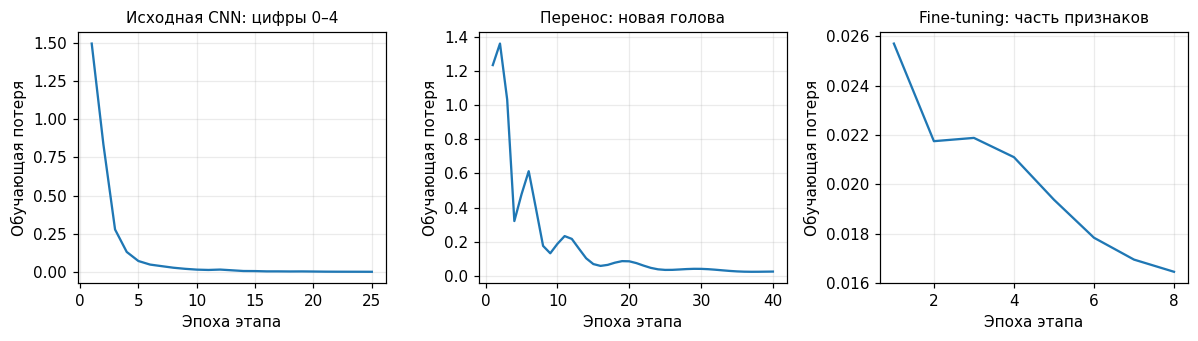

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, history, title in zip(
    axes,
    [source_history, head_history, fine_history],
    ['Исходная CNN: цифры 0–4', 'Перенос: новая голова', 'Fine-tuning: часть признаков'],
):
    ax.plot(history.index, history['Потеря'])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Эпоха этапа')
    ax.set_ylabel('Обучающая потеря')
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Разбор графиков этапов.**

- `plt.subplots(1, 3, ...)` создаёт три панели. `zip(...)` одновременно перебирает панели, соответствующие таблицы истории и названия; `for ax, history, title in ...` распаковывает тройку значений.
- `.index` содержит номера эпох, `history['Потеря']` выбирает нужный столбец. `ax.plot(...)` соединяет записанные значения линией.
- `set_title(...)`, `set_xlabel(...)` и `set_ylabel(...)` подписывают опыт и оси. `grid(alpha=0.25)` добавляет полупрозрачную сетку; `tight_layout()` размещает подписи, `plt.show()` выводит рисунок.

У панелей отдельные вертикальные масштабы. Исходная задача имеет пять классов, новая — два; сравнивать абсолютные потери между этими задачами как рейтинг нельзя. При fine-tuning модель начинает с уже обученной головы и признаков, а не с нулевого знания.

У новой головы потеря в начале может временно увеличиваться: линия обучения не обязана уменьшаться на каждой эпохе. На графиках нужно читать записанный ход опыта, а вывод о новых изображениях делать по отдельной проверке.

## 6. YOLO: обнаружение объектов на фотографии

### Что добавляется к классификации

Для сцены мало одного ответа «автобус»: на ней могут одновременно находиться транспорт и люди. Детектор возвращает **несколько рамок**, класс и оценку для каждой. Координаты `x1, y1, x2, y2` обозначают левый верхний и правый нижний углы. Начало координат изображения находится сверху слева: x растёт вправо, y — вниз.

Семейство YOLO обрабатывает сцену сетью, которая получает признаки и предсказывает расположение объектов вместе с классами. Конкретная архитектура и обработка выхода зависят от версии. В этом файле используется фиксированный **YOLOv8n**: компактный вариант с предобученными весами. Его backbone выделяет признаки, neck объединяет признаки разных масштабов, а detection head выдаёт кандидатов рамок и классов. [Работа о первоначальном YOLO](https://arxiv.org/abs/1506.02640), [описание YOLOv8](https://docs.ultralytics.com/models/yolov8/).

Это готовая модель, обученная на COCO с заданным набором классов. Она не начинает автоматически распознавать произвольные предметы с новыми именами. Для своей задачи потребуются размеченные изображения, согласованные классы и отдельное обучение. В разметке detection каждому объекту соответствует рамка и класс; один класс на всё изображение недостаточен.

В распространённом текстовом формате YOLO строка разметки содержит номер класса, центр рамки, ширину и высоту в относительных координатах. **Предсказание модели не становится правильной разметкой само по себе.** В нашем примере достоверная разметка сцены не задана, поэтому по одной фотографии не вычисляется качество детектора.

Откроем локальную фотографию и загрузим локальные предобученные веса YOLOv8n. Явно проверим наличие файлов до создания модели: ноутбук не должен незаметно запрашивать веса по сети. Покажем размеры изображения и названия двух классов, которые будут встречаться в результате.

In [20]:
yolo_weights_path = data_dir / 'yolov8n.pt'
scene_path = data_dir / 'автобус.jpg'
for local_path in [yolo_weights_path, scene_path]:
    if not local_path.is_file():
        raise FileNotFoundError(f'Нужен локальный файл: {local_path.resolve()}')
with Image.open(scene_path) as opened_scene:
    scene_image = opened_scene.convert('RGB')
yolo_model = YOLO(str(yolo_weights_path), task='detect')
class_translations = {'person': 'человек', 'bus': 'автобус'}
print('Изображение: ширина, высота:', scene_image.size)
print('Предобученных классов:', len(yolo_model.names))
print('Класс 0:', yolo_model.names[0], '| класс 5:', yolo_model.names[5])

Изображение: ширина, высота: (810, 1080)
Предобученных классов: 80
Класс 0: person | класс 5: bus


**Разбор локального ввода.**

- Оператор `/` у `data_dir` строит два пути. Цикл `for` проверяет их по очереди. `.is_file()` возвращает логическое значение; `if not ...` выбирает действие при отсутствии файла.
- `raise FileNotFoundError(...)` останавливает выполнение с понятным сообщением. Строка `f'...'` подставляет абсолютный путь через `.resolve()`. Это явная ошибка подготовки файлов, а не скрытый пропуск примера.
- `with Image.open(...) as opened_scene` открывает фотографию; `.convert('RGB')` создаёт согласованное цветное изображение. Pillow использует RGB. В других интерфейсах, например при передаче массива OpenCV, может ожидаться другой порядок каналов.
- `YOLO(str(yolo_weights_path), task='detect')` загружает выбранные локальные веса для обнаружения объектов. `str(...)` переводит путь в строку. Это числовые обученные веса, в отличие от рассмотрения VGG и ResNet на `meta`.
- `class_translations` — словарь русских подписей для встречающихся классов. `yolo_model.names` хранит имена предобученных классов, `[0]` и `[5]` выбирают человека и автобус. `len(...)`, `.size` и `print(...)` показывают сведения.

Полученные номера классов относятся к обучению этой модели. Они не совпадают с номерами цифр в предыдущих примерах и должны читаться через её собственный словарь имён.

Выполним настоящее обнаружение на CPU и преобразуем результат в таблицу рамок. Зададим размер внутренней обработки, порог оценки и параметр подавления дублирующих рамок. Ultralytics самостоятельно подготавливает изображение и возвращает координаты относительно исходной фотографии.

In [21]:
yolo_result = yolo_model.predict(
    source=scene_image, imgsz=320, conf=0.25, iou=0.5,
    device='cpu', max_det=20, verbose=False, save=False,
)[0]
detected_boxes = yolo_result.boxes.xyxy.cpu().numpy()
detected_scores = yolo_result.boxes.conf.cpu().numpy()
detected_classes = yolo_result.boxes.cls.cpu().numpy().astype(int)
detected_names = [yolo_model.names[class_id] for class_id in detected_classes]
detections_table = pd.DataFrame(detected_boxes, columns=['x1', 'y1', 'x2', 'y2'])
detections_table['Класс модели'] = detected_names
detections_table['Подпись'] = [class_translations.get(name, name) for name in detected_names]
detections_table['Оценка'] = detected_scores
display(detections_table.round(3))
print('Размер исходного изображения в результате H, W:', yolo_result.orig_shape)

,x1,y1,x2,y2,Класс модели,Подпись,Оценка
0,46.904,394.448,232.236,903.602,person,человек,0.849
1,6.391,227.593,800.310,752.656,bus,автобус,0.825
2,220.096,402.599,347.912,854.139,person,человек,0.750
3,670.360,378.205,809.565,872.113,person,человек,0.635


Размер исходного изображения в результате H, W: (1080, 810)


**Разбор вызова YOLO и результата.**

- `yolo_model.predict(...)` принимает `source=scene_image`. `imgsz=320` задаёт размер внутренней обработки с учётом правил модели; исходный файл не перезаписывается. `device='cpu'` выбирает CPU, `verbose=False` отключает подробный журнал, `save=False` — автоматическое сохранение картинок, `max_det=20` ограничивает число возвращаемых объектов.
- `conf=0.25` отсекает слабые кандидаты по оценке. `iou=0.5` управляет обработкой пересекающихся рамок YOLOv8, а не является ещё одним порогом уверенности. Эти параметры имеют разные назначения.
- `predict` возвращает список результатов; `[0]` выбирает единственное входное изображение. `.boxes.xyxy` содержит углы рамок, `.boxes.conf` — оценки, `.boxes.cls` — номера классов. `.cpu().numpy()` получает массивы на CPU, `.astype(int)` согласует тип номеров классов.
- Список `[yolo_model.names[class_id] for class_id in detected_classes]` читает имена для каждого номера. `pd.DataFrame(..., columns=...)` задаёт четыре столбца координат. Последующие присваивания добавляют имена и оценки.
- `class_translations.get(name, name)` берёт русский перевод, а если его нет — исходное имя. `.round(3)` округляет только показываемую копию таблицы; `display(...)` выводит её. `.orig_shape` сообщает исходные высоту и ширину, `print(...)` показывает их.

Координаты относятся к исходной фотографии, поэтому их можно сразу использовать поверх неё. Оценка детектора не является гарантией правильности и не должна автоматически трактоваться как откалиброванная вероятность события. Интерфейсы входов и выходов описаны в [справке Ultralytics](https://docs.ultralytics.com/modes/predict/).

В этом запуске получены четыре рамки: автобус и три человека. Оценки лежат примерно от 0,635 до 0,849. Форма исходной фотографии `(1080, 810)` указана как высота и ширина, а Pillow ранее показал `(810, 1080)` как ширину и высоту: это один и тот же снимок.

Нарисуем полученные рамки на исходной фотографии. Подпишем класс и оценку, затем сохраним изображение с результатом в папку материала. Координаты используем из таблицы без повторного изменения масштаба.

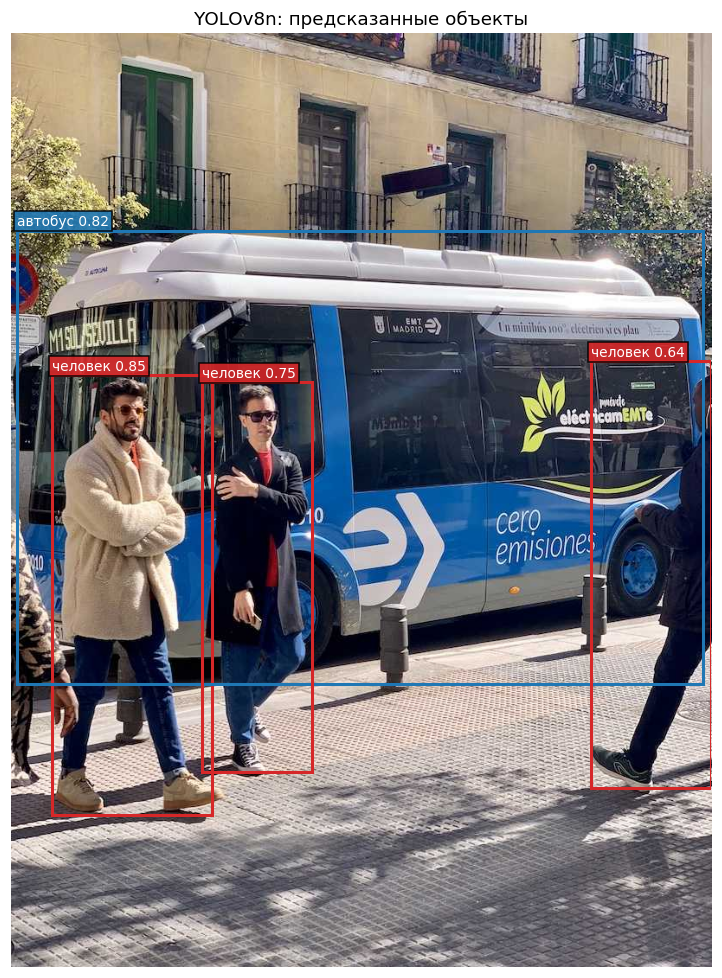

In [22]:
fig, ax = plt.subplots(figsize=(7, 9))
ax.imshow(scene_image)
for _, row in detections_table.iterrows():
    color = 'tab:blue' if row['Класс модели'] == 'bus' else 'tab:red'
    rectangle = Rectangle(
        (row['x1'], row['y1']), row['x2'] - row['x1'], row['y2'] - row['y1'],
        fill=False, edgecolor=color, linewidth=2,
    )
    ax.add_patch(rectangle)
    ax.text(
        row['x1'], max(row['y1'] - 6, 12), f"{row['Подпись']} {row['Оценка']:.2f}",
        color='white', fontsize=9, bbox={'facecolor': color, 'alpha': 0.9, 'pad': 2},
    )
ax.set_title('YOLOv8n: предсказанные объекты')
ax.axis('off')
fig.tight_layout()
detection_image_path = result_dir / 'YOLO_обнаруженные_объекты.png'
fig.savefig(detection_image_path, dpi=130, bbox_inches='tight')
plt.show()

**Разбор рамок и подписей.**

- `plt.subplots(...)` создаёт одну панель, `ax.imshow(scene_image)` показывает исходную фотографию. `.iterrows()` перебирает строки таблицы; `_` принимает индекс, который здесь не используется, `row` содержит значения строки.
- Выражение `'tab:blue' if ... else 'tab:red'` выбирает цвет по классу. `row['...']` обращается к столбцу текущей строки. Автобус и люди получают разные цвета.
- `Rectangle((x1, y1), width, height, ...)` создаёт прямоугольник от верхнего левого угла. Ширина и высота получаются из координат двух углов. `fill=False` оставляет фотографию видимой, `edgecolor` задаёт цвет границы, `linewidth` — толщину. `ax.add_patch(...)` добавляет рамку на панель.
- `ax.text(...)` размещает подпись над рамкой. `max(..., 12)` не позволяет подписи уйти слишком высоко. В строке `f"...{...:.2f}"` оценка показывается с двумя знаками после точки; `bbox` задаёт фон текста, `alpha` — его прозрачность, `pad` — отступ.
- `set_title(...)`, `axis('off')` и `tight_layout()` оформляют рисунок. Оператор `/` строит путь; `fig.savefig(..., dpi=130, bbox_inches='tight')` сохраняет PNG с подрезкой внешних полей. `plt.show()` показывает тот же результат.

Нарисованные прямоугольники — предсказания сети. Визуально разумная рамка ещё не заменяет проверку по независимой разметке. В этой сцене один объект может частично закрывать другой; детектор работает по видимой информации и способен пропускать объекты.

У левого края фотографии видна часть ещё одного человека, для которой в этом запуске отдельной рамки нет. Это наглядный пример пропуска частично видимого объекта; разумный вид остальных рамок не означает, что детектор обнаружил всё.

### Порог оценки и пересекающиеся рамки

Повышение порога `conf` сокращает число показываемых слабых результатов, но может удалить верные находки. Порог не улучшает внутреннее понимание сцены и не переобучает сеть.

Несколько кандидатов могут описывать один объект. В используемом YOLOv8 применяется **NMS**, подавление немаксимальных рамок: при сильном пространственном совпадении сохраняются более высоко оценённые кандидаты. **IoU** — мера пространственного совпадения рамок от 0 до 1; 0 означает отсутствие общей площади, 1 — совпадение. Формулу здесь не вводим.

Пересечение рамок само по себе не означает дубликат: рядом могут находиться разные объекты. В обычном режиме YOLOv8 подавление учитывает классы. Другие версии семейства могут использовать иной способ формирования финальных рамок; параметры нужно читать для выбранной модели.

Повторим обнаружение с двумя заранее заданными порогами оценки. Остальные настройки сохраним. Сравним, сколько рамок и каких классов осталось; по одной фотографии правильность порога определить нельзя.

In [23]:
threshold_rows = []
for threshold in [0.25, 0.75]:
    threshold_result = yolo_model.predict(
        source=scene_image, imgsz=320, conf=threshold, iou=0.5,
        device='cpu', max_det=20, verbose=False, save=False,
    )[0]
    threshold_names = [yolo_model.names[int(value)] for value in threshold_result.boxes.cls.tolist()]
    threshold_rows.append({
        'Порог оценки': threshold,
        'Всего рамок': len(threshold_names),
        'Людей': threshold_names.count('person'),
        'Автобусов': threshold_names.count('bus'),
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table)

,Порог оценки,Всего рамок,Людей,Автобусов
0,0.25,4,3,1
1,0.75,3,2,1


**Разбор сравнения порогов.**

- `threshold_rows = []` создаёт список строк. `for threshold in [0.25, 0.75]` перебирает два значения; каждый раз `.predict(...)` выполняет реальное обнаружение с соответствующим `conf`. Модель и её веса остаются теми же.
- `source`, `imgsz`, `iou`, `device`, `max_det`, `verbose` и `save` повторяют исходные настройки. `[0]` выбирает результат одного изображения.
- `.boxes.cls.tolist()` переводит номера классов в список. В списковом выражении `int(value)` получает целый ключ для `yolo_model.names[...]`; собираются названия найденных классов.
- `.append({...})` добавляет итог одного порога. `len(...)` считает все рамки, `.count('person')` и `.count('bus')` — соответствующие имена в списке. `pd.DataFrame(...)` и `display(...)` показывают сравнение.

Каждая строка описывает отдельный запуск с одинаковыми весами. Удалённый результат мог быть как ошибкой, так и настоящим объектом. Для выбора рабочего порога нужны размеченные примеры будущих условий, а не только эстетичность одной картинки.

При пороге 0,25 остаются четыре рамки: автобус и три человека. При 0,75 — три: автобус и два человека. Исчезает рамка человека справа с оценкой около 0,635. У среднего человека исходная оценка около 0,750353, поэтому он остаётся при пороге 0,75, хотя в округлённом выводе его оценка выглядит как 0,750.

Отделим механизм NMS от самой модели. Зададим три учебные рамки **одного класса**: первые две почти совпадают, третья находится отдельно. Покажем их пространственное совпадение и номера рамок, которые сохранит готовая операция Torchvision.

In [24]:
demo_boxes = torch.tensor([[10.0, 10.0, 70.0, 70.0], [12.0, 12.0, 68.0, 68.0], [85.0, 12.0, 115.0, 50.0]])
demo_scores = torch.tensor([0.92, 0.81, 0.77])
overlap_table = pd.DataFrame(box_iou(demo_boxes, demo_boxes).numpy(), index=['Рамка 0', 'Рамка 1', 'Рамка 2'], columns=['Рамка 0', 'Рамка 1', 'Рамка 2'])
kept_indices = nms(demo_boxes, demo_scores, iou_threshold=0.5)
display(overlap_table)
print('Сохранены номера:', kept_indices.tolist())

,Рамка 0,Рамка 1,Рамка 2
Рамка 0,1.0000,0.8711,0.0
Рамка 1,0.8711,1.0000,0.0
Рамка 2,0.0000,0.0000,1.0


Сохранены номера: [0, 2]


**Разбор NMS на заданных рамках.**

- `torch.tensor(...)` создаёт рамки формы `(3, 4)` и их оценки формы `(3,)`. В каждой строке последовательно записаны `x1, y1, x2, y2`; правый нижний угол расположен правее и ниже левого верхнего.
- `box_iou(demo_boxes, demo_boxes)` возвращает таблицу попарного совпадения этих рамок. `.numpy()` готовит числа для `pd.DataFrame(...)`, `index` и `columns` задают одинаковые подписи строк и столбцов, `display(...)` показывает результат.
- `nms(..., iou_threshold=0.5)` возвращает индексы сохранённых рамок. Она учитывает пространственное совпадение и порядок оценок. `.tolist()` превращает индексы в обычный список, `print(...)` выводит его.

Остаются рамки 0 и 2. Почти совпадающая рамка 1 имеет меньшую оценку и подавляется. Рамка 2 остаётся, поскольку находится отдельно. Эта самостоятельная операция не получает классы: мы заранее выбрали рамки одного класса. Её нельзя бездумно применять сразу ко всем разным классам.

В готовом `yolo_result` нужная обработка YOLOv8 уже выполнена; повторно применять этот учебный NMS к его таблице не требуется. Поведение операции описано в [документации Torchvision](https://docs.pytorch.org/vision/0.26/generated/torchvision.ops.nms.html).

## 7. Сохраняем результаты опыта

Сохраним небольшие состояния двух обученных CNN, таблицу рамок и описание запуска. Здесь используем знакомое сохранение `state_dict`; порядок действий по загрузке модели уже разобран в материале № 12. В состоянии перенесённой CNN будет записан итог fine-tuning. Метаданные отдельно фиксируют, что первая голова распознаёт 0–4, а новая различает 6 и 9.

Запишем локальные результаты и фактические сведения о моделях. Таблица рамок будет CSV, описание — JSON, веса небольших CNN — собственные файлы PyTorch. Исходные предобученные веса YOLO повторно не сохраняем: путь к ним указан в описании.

In [25]:
source_checkpoint_path = result_dir / 'CNN_исходная.pt'
transfer_checkpoint_path = result_dir / 'CNN_после_переноса.pt'
torch.save({'model_state': source_cnn.state_dict(), 'classes': 5}, source_checkpoint_path)
torch.save({'model_state': transfer_cnn.state_dict(), 'classes': 2}, transfer_checkpoint_path)
detection_table_path = result_dir / 'YOLO_рамки.csv'
detections_table.to_csv(detection_table_path, index=False, encoding='utf-8-sig')

run_description = {
    'версии': {'python': sys.version.split()[0], 'torch': torch.__version__,
               'torchvision': torchvision.__version__, 'ultralytics': ultralytics.__version__},
    'вычисления': 'CPU; полные VGG и ResNet: meta, проверка структуры',
    'исходная_задача': {'классы': [0, 1, 2, 3, 4], 'accuracy': source_accuracy},
    'новая_задача': {'метки': {'0': 6, '1': 9}, 'обучающих_изображений': len(target_train_indices),
                     'accuracy_головы': head_accuracy, 'accuracy_fine_tuning': fine_accuracy},
    'перенос': {'признаки_заморожены_при_обучении_головы': features_unchanged,
                'голова_изменилась': head_changed,
                'первая_свёртка_сохранилась': first_conv_unchanged,
                'вторая_свёртка_дообучена': second_conv_changed},
    'yolo': {'модель': str(yolo_weights_path), 'предобученная': True,
             'размер_обработки': 320, 'порог_оценки': 0.25, 'рамок': len(detections_table)},
    'файлы': [source_checkpoint_path.name, transfer_checkpoint_path.name,
              detection_table_path.name, detection_image_path.name],
}
description_path = result_dir / 'описание_запуска.json'
description_path.write_text(json.dumps(run_description, ensure_ascii=False, indent=2), encoding='utf-8')
print('Описание:', description_path.resolve())
display(pd.DataFrame({'Файл': run_description['файлы']}))

Описание: C:\Users\user\Desktop\courses\shift\3928_Artificial_Intelligence_Specialist\13_результаты_компьютерное_зрение\описание_запуска.json


,Файл
0,CNN_исходная.pt
1,CNN_после_переноса.pt
2,YOLO_рамки.csv
3,YOLO_обнаруженные_объекты.png


**Разбор сохранения и описания.**

- Оператор `/` строит пути. `.state_dict()` получает обученное состояние каждой CNN; `torch.save({...}, ...)` записывает его вместе с числом выходных классов. Для восстановления нужен класс `DigitCNN` из этого ноутбука и соответствующее значение `classes`.
- `.to_csv(..., index=False, encoding='utf-8-sig')` записывает таблицу рамок без дополнительного столбца индекса. Указанная кодировка удобна для русских заголовков в настольных табличных редакторах.
- `run_description` — словарь с вложенными словарями, списками, числами и логическими значениями. `.__version__` читает версии, `sys.version.split()[0]` выбирает краткую версию Python. `str(...)` записывает путь текстом, `len(...)` считает изображения и рамки, `.name` берёт имя файла.
- `json.dumps(..., ensure_ascii=False, indent=2)` создаёт читаемый текст с русскими символами. `.write_text(..., encoding='utf-8')` записывает его; `.resolve()` и `print(...)` показывают путь. `pd.DataFrame(...)` и `display(...)` перечисляют основные файлы.

В JSON одновременно зафиксированы реальные числовые этапы и отдельная проверка структуры стандартных архитектур. Флаги переноса получены сравнением весов, а не просто вписаны как предположение. CSV содержит предсказанные рамки, а не эталонную разметку фотографии.

## 8. Как читать полученный процесс

Изображение сначала получает согласованные каналы, тип и порядок осей. Свёртки преобразуют локальные области в карты признаков, уменьшение размера меняет пространственное представление, а голова задаёт выход под конкретную задачу.

VGG показывает последовательные группы свёрток; ResNet добавляет обходные связи. Это способы организации сети, которые нужно отличать от конкретных обученных весов. В transfer learning мы использовали действительное обученное состояние, сменили голову, проверили замораживание и затем разрешили изменение части признаков.

YOLO решает обнаружение: на выходе несколько рамок, классы и оценки. Порог оценки и обработка пересечений управляют выводом, но не заменяют обучение и проверку по разметке. Следующий раздел курса относится к NLP; способы работы с текстом здесь не рассматриваются.

### Справочные источники

[Conv2d в PyTorch](https://docs.pytorch.org/docs/2.11/generated/torch.nn.Conv2d.html), [VGG-16 в Torchvision 0.26](https://docs.pytorch.org/vision/0.26/models/generated/torchvision.models.vgg16.html), [ResNet-18](https://docs.pytorch.org/vision/0.26/models/generated/torchvision.models.resnet18.html), [встроенный набор цифр](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html), [руководство Ultralytics по обнаружению](https://docs.ultralytics.com/tasks/detect/). Это дополнительные ссылки; локальные выполненные примеры не требуют их открытия.